## Coffee Shop Sales: Clustering

### 1. Set up Spark and load data

In [13]:
import os

os.environ["JAVA_HOME"] = r"C:\Program Files\Java\jdk-17"
os.environ["PATH"] = os.environ["JAVA_HOME"] + r"\bin;" + os.environ["PATH"]

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("CoffeeShopClustering")
    .master("local[2]")
    .config("spark.ui.enabled", "false")
    .getOrCreate()
)

print("Spark Session Initialized Successfully!")

Spark Session Initialized Successfully!


In [14]:
file_path = r"D:\Projects\Coffee Shop Sales - Cluster Computing\Dataset\Coffee Shop Sales.csv"
df = spark.read.csv(
    file_path,
    header = True,
    inferSchema = True
)
print("Total Rows:", df.count())
print("Total Columns:", len(df.columns))

df.show(5, truncate=False)

Total Rows: 149116
Total Columns: 11
+--------------+----------------+-------------------+---------------+--------+---------------+----------+----------+------------------+---------------------+---------------------------+
|transaction_id|transaction_date|transaction_time   |transaction_qty|store_id|store_location |product_id|unit_price|product_category  |product_type         |product_detail             |
+--------------+----------------+-------------------+---------------+--------+---------------+----------+----------+------------------+---------------------+---------------------------+
|1             |01-01-2023      |2026-10-20 07:06:11|2              |5       |Lower Manhattan|32        |3.0       |Coffee            |Gourmet brewed coffee|Ethiopia Rg                |
|2             |01-01-2023      |2026-10-20 07:08:56|2              |5       |Lower Manhattan|57        |3.1       |Tea               |Brewed Chai tea      |Spicy Eye Opener Chai Lg   |
|3             |01-01-2023      |

### 2. Aggregate product-level metrics

In [15]:
from pyspark.sql.functions import sum, avg, count, col

product_data = (
    df.groupBy("product_id", "product_category", "product_type")
    .agg(
        sum(col("transaction_qty")).alias("total_quantity_sold"),
        avg(col("unit_price")).alias("average_price"),
        count("*").alias("total_transactions")
    )
)

print("Product-level aggregation completed!")
print("Number of product groups:", product_data.count())

product_data.show(10, truncate=False)

Product-level aggregation completed!
Number of product groups: 80
+----------+------------------+---------------------+-------------------+------------------+------------------+
|product_id|product_category  |product_type         |total_quantity_sold|average_price     |total_transactions|
+----------+------------------+---------------------+-------------------+------------------+------------------+
|21        |Packaged Chocolate|Drinking Chocolate   |148                |13.329999999999998|148               |
|51        |Tea               |Brewed Black tea     |4245               |3.0               |2702              |
|42        |Tea               |Brewed herbal tea    |4325               |2.5               |2792              |
|2         |Coffee beans      |House blend Beans    |183                |18.0              |183               |
|81        |Branded           |Clothing             |221                |27.8868778280543  |221               |
|61        |Drinking Chocolate|Hot cho

### 3. Assemble and scale clustering features

In [16]:
from pyspark.ml.feature import VectorAssembler, StandardScaler

# Select numerical features
feature_cols = [
    "total_quantity_sold",
    "average_price",
    "total_transactions"
]

# Combine features into a vector
assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="raw_features"
)

product_features = assembler.transform(product_data)

# Standardize features
scaler = StandardScaler(
    inputCol="raw_features",
    outputCol="scaled_features",
    withMean=True,
    withStd=True
)

scaler_model = scaler.fit(product_features)
scaled_data = scaler_model.transform(product_features)

print("Features scaled successfully!")

scaled_data.select(
    "product_id",
    "raw_features",
    "scaled_features"
).show(5, truncate=False)

Features scaled successfully!
+----------+--------------------------------+------------------------------------------------------------+
|product_id|raw_features                    |scaled_features                                             |
+----------+--------------------------------+------------------------------------------------------------+
|21        |[148.0,13.329999999999998,148.0]|[-1.3807188127138146,0.9297556666595342,-1.4653374793713763]|
|51        |[4245.0,3.0,2702.0]             |[0.8526345804415904,-0.4974725613847903,0.715653762980962]  |
|42        |[4325.0,2.5,2792.0]             |[0.8962441170421352,-0.5665542761981651,0.7925093666660483] |
|2         |[183.0,18.0,183.0]              |[-1.3616396404510762,1.574978883016456,-1.435449189049398]  |
|81        |[221.0,27.8868778280543,221.0]  |[-1.3409251105658173,2.9409838320411086,-1.4029990452712506]|
+----------+--------------------------------+------------------------------------------------------------+
only sh

### 4. Train the K-Means model

In [17]:
from pyspark.ml.clustering import KMeans

kmeans = KMeans(
    featuresCol="scaled_features",
    predictionCol="cluster",
    k=3,
    seed=42
)

kmeans_model = kmeans.fit(scaled_data)

print("K-Means model trained successfully!")

K-Means model trained successfully!


### 5. Assign products to clusters

In [18]:
clustered_data = kmeans_model.transform(scaled_data)

clustered_data.select(
    "product_id",
    "product_category",
    "product_type",
    "total_quantity_sold",
    "average_price",
    "total_transactions",
    "cluster"
).show(15, truncate=False)

+----------+------------------+---------------------+-------------------+------------------+------------------+-------+
|product_id|product_category  |product_type         |total_quantity_sold|average_price     |total_transactions|cluster|
+----------+------------------+---------------------+-------------------+------------------+------------------+-------+
|21        |Packaged Chocolate|Drinking Chocolate   |148                |13.329999999999998|148               |0      |
|51        |Tea               |Brewed Black tea     |4245               |3.0               |2702              |1      |
|42        |Tea               |Brewed herbal tea    |4325               |2.5               |2792              |1      |
|2         |Coffee beans      |House blend Beans    |183                |18.0              |183               |0      |
|81        |Branded           |Clothing             |221                |27.8868778280543  |221               |0      |
|61        |Drinking Chocolate|Hot choco

In [19]:
clustered_data = kmeans_model.transform(scaled_data)

clustered_data.select(
    "product_id",
    "product_category",
    "product_type",
    "total_quantity_sold",
    "average_price",
    "total_transactions",
    "cluster"
).show(15, truncate=False)

+----------+------------------+---------------------+-------------------+------------------+------------------+-------+
|product_id|product_category  |product_type         |total_quantity_sold|average_price     |total_transactions|cluster|
+----------+------------------+---------------------+-------------------+------------------+------------------+-------+
|21        |Packaged Chocolate|Drinking Chocolate   |148                |13.329999999999998|148               |0      |
|51        |Tea               |Brewed Black tea     |4245               |3.0               |2702              |1      |
|42        |Tea               |Brewed herbal tea    |4325               |2.5               |2792              |1      |
|2         |Coffee beans      |House blend Beans    |183                |18.0              |183               |0      |
|81        |Branded           |Clothing             |221                |27.8868778280543  |221               |0      |
|61        |Drinking Chocolate|Hot choco

### 6. Summarize cluster characteristics

In [20]:
from pyspark.sql.functions import avg, count

cluster_summary = (
    clustered_data
    .groupBy("cluster")
    .agg(
        count("*").alias("number_of_products"),
        avg("total_quantity_sold").alias("avg_quantity_sold"),
        avg("average_price").alias("avg_product_price"),
        avg("total_transactions").alias("avg_transactions")
    )
    .orderBy("cluster")
)

cluster_summary.show(truncate=False)

+-------+------------------+------------------+------------------+------------------+
|cluster|number_of_products|avg_quantity_sold |avg_product_price |avg_transactions  |
+-------+------------------+------------------+------------------+------------------+
|0      |24                |179.20833333333334|15.033312782146242|174.875           |
|1      |41                |4299.463414634146 |3.075736464841891 |2833.829268292683 |
|2      |15                |2259.4            |2.7429373702981743|1915.4666666666667|
+-------+------------------+------------------+------------------+------------------+



### 7. Visualize cluster profiles

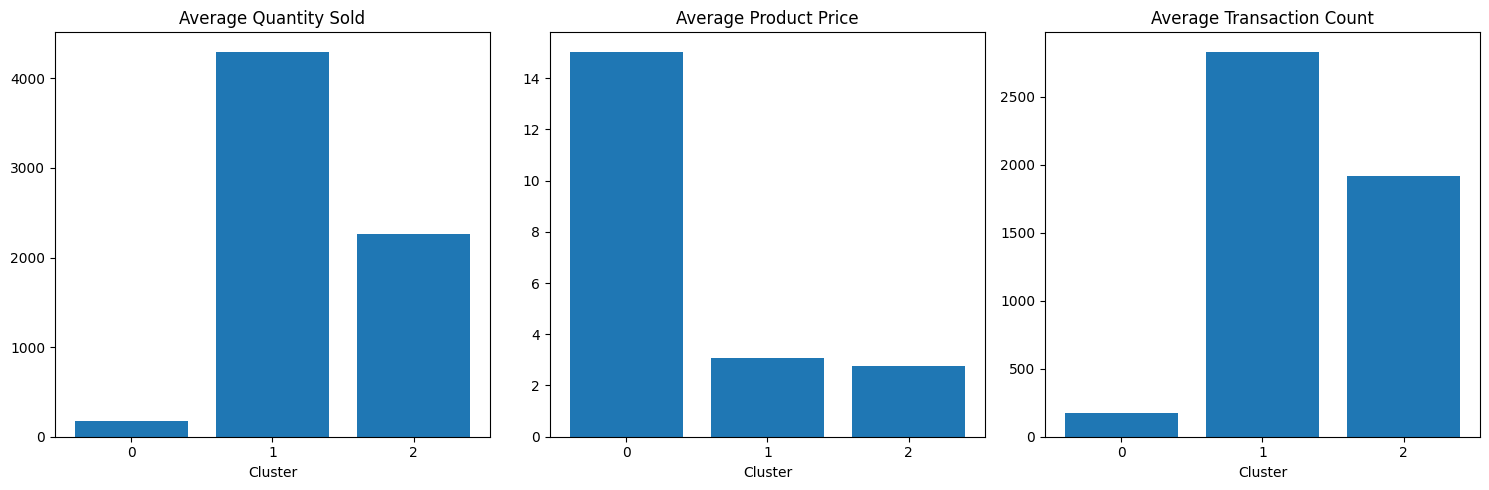

In [21]:
import matplotlib.pyplot as plt

cluster_pdf = cluster_summary.toPandas().sort_values("cluster")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].bar(cluster_pdf["cluster"].astype(str), cluster_pdf["avg_quantity_sold"])
axes[0].set_title("Average Quantity Sold")
axes[0].set_xlabel("Cluster")

axes[1].bar(cluster_pdf["cluster"].astype(str), cluster_pdf["avg_product_price"])
axes[1].set_title("Average Product Price")
axes[1].set_xlabel("Cluster")

axes[2].bar(cluster_pdf["cluster"].astype(str), cluster_pdf["avg_transactions"])
axes[2].set_title("Average Transaction Count")
axes[2].set_xlabel("Cluster")

plt.tight_layout()
plt.show()